# Connectome Spectrum Transform from tractography
We generate a high resolution connectome from tractography data. The method associates the endpoints of streamlines to closest sources. Because the sources are in close proximity (~2mm), associating the endpoints to exactly one source is a point of error. Therefore, following [Sina Mansour et. al (2020)](https://www.sciencedirect.com/science/article/pii/S1053811920311800?via%3Dihub#sec0035)'s methodology, we smooth the connectivity to disperse the endpoint of streamlines across vertices in the proximity of the endpoint. 

## 📦 Imports

In [8]:
import mindmap as mm
import scipy as sp
import numpy as np
import pygsp
import nibabel as nib
import pyvista as pv

## 🧠 Data

In [9]:
# configuration
sub    = "vepcon_sub-10" 
env    = mm.io.read_config("../configurations/simf.yml")
mm_dir = env["MM_DIR"]

# data
data = mm.io.read_dataset(sub, "fwd", "cras", "tracto", "diff_affine", "parc", "ctx_mask")

# parameters
threshold = 5           # maximum distance to attach streamline in [mm] (consider dipole spacing divided by 2)
fwhm = 12               # full width half maximum (gaussian property for smoothing connectivity)
epsilon = 1e-07          # influences smoothing radius
dim = 2                 # smoothing dimensionality (surface is 2d)

 ⚙️ **<font color=green>Align sources and streamlines </font>**: To align the sources with the streamline endpoints, we scale the sources to [mm] and apply the CRAS translation. Next, we also apply the inverse diffusion affine transform, as the diffusion space is slightly different from the T1 space.

In [10]:
# extract source positions
pos = mm.utils.get_src_position(data["fwd"]["src"])
pos = pos*1000 + data["cras"]

# extract source geodesic distances 
geodist = mm.utils.get_geodist(data["fwd"]["src"]) * 1000   # in [mm]

# extract stream line endpoints
voxel_size = data["tracto"].header["voxel_sizes"].reshape(1,-1)
starts     = np.array([stream[0] for stream in data["tracto"].streamlines]) / voxel_size
ends       = np.array([stream[-1] for stream in data["tracto"].streamlines]) / voxel_size
starts     = nib.affines.apply_affine(np.linalg.inv(data["diff_affine"]), starts)
ends       = nib.affines.apply_affine(np.linalg.inv(data["diff_affine"]), ends)

 ⚙️ **<font color=green>Delete streamlines having endpoints outside of cortical regions</font>**: Sources are only in the cortex, so we consider only cortical-cortical streamlines.

In [11]:
inv_affine = np.linalg.inv(data["ctx_mask"].affine)
volume     = data["ctx_mask"].get_fdata()

retain = []
for points in [starts, ends]:
    vox  = nib.affines.apply_affine(inv_affine, points)                 # transfer points to T1 voxel ids
    vox  = np.round(vox).astype(int)                                   
    mask = volume[vox[:,0], vox[:,1], vox[:,2]].astype(bool)            # retrieve ctx mask value at voxel postion

    retain.append(mask)
    
retain = retain[0] * retain[1]        # retain is True if start and end point are in the cortical area.
print(f"Quantity of streamlines removed: {np.sum(~retain)/len(retain)*100:.3}%")

dismiss_s = starts[~retain] # for plotting
dismiss_e = ends[~retain]

starts = starts[retain]
ends   = ends[retain]

Quantity of streamlines removed: 47.4%


#### 🌟 Visualize sources and streamline endpoints alignment 

In [12]:
import pyvista as pv 

# points
src       = pv.PolyData(nib.affines.apply_affine(inv_affine, pos))
retained  = pv.PolyData(nib.affines.apply_affine(inv_affine, np.vstack([starts, ends])))
dismissed = pv.PolyData(nib.affines.apply_affine(inv_affine, np.vstack([dismiss_s, dismiss_e])))

# mask
ctx_mask = pv.ImageData(dimensions=data["ctx_mask"].shape, spacing=(1,1,1), origin=(0,0,0))
ctx_mask.point_data["scalars"] = data["ctx_mask"].get_fdata().flatten(order="F")

p = pv.Plotter()
p.add_mesh(src, color="black", render_points_as_spheres=True, point_size=8)
p.add_mesh(retained, color="green")
#p.add_mesh(dismissed, color="red", opacity=0.1)
p.add_mesh(ctx_mask.contour(3), color="white", opacity=0.2)
p.show()

Widget(value='<iframe src="http://localhost:38617/index.html?ui=P_0x79ecbc215d90_3&reconnect=auto" class="pyvi…

#### 🌟 Visualize region-based connectome
We start by visualizing the region-based connectome to check the quality of the tractogram. The regions with 0 degree are sub-cortical regions that we omitted previously.

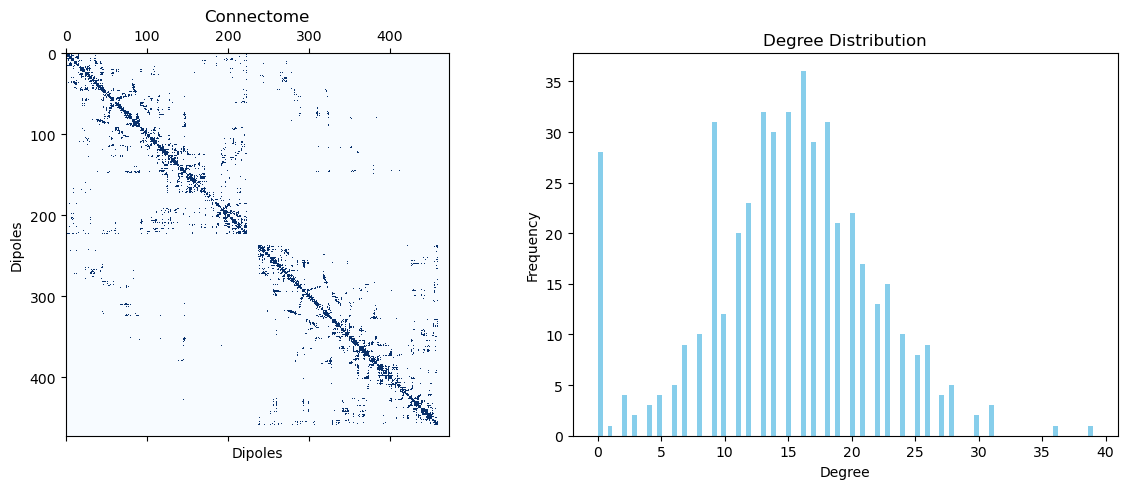

In [13]:
start_lab = data["parc"].label_points(starts, id=True)
end_lab   = data["parc"].label_points(ends, id=True)

n = data["parc"].n_regions

conn = np.zeros(shape=(n,n))
conn[start_lab, end_lab] = 1

mm.viz.plot_connectome(conn)

⚙️ **<font color=green>Build connectivity from closest sources</font>**: Use a closest neighborhood algorithm to associate each streamline endpoint to its closest dipole.

In [14]:
# find closest source to streamlines endpoints
kd_tree = sp.spatial.cKDTree(pos)
start_dists, start_idx = kd_tree.query(starts)
end_dists, end_idx     = kd_tree.query(ends)

# create incidence matrices
n, s = data["fwd"]["nsource"], len(starts)
M1 = sp.sparse.csr_array((np.ones(len(start_idx)), (start_idx, range(s))), shape=(n,s))
M2 = sp.sparse.csr_array((np.ones(len(end_idx)), (end_idx, range(s))), shape=(n,s))

# compute structural connectivity matrix
sc = (M1 @ M2.T) + (M2 @ M1.T)

#### 🌟 Visualize dipole-based connectome

Number of isolated dipoles: 1788


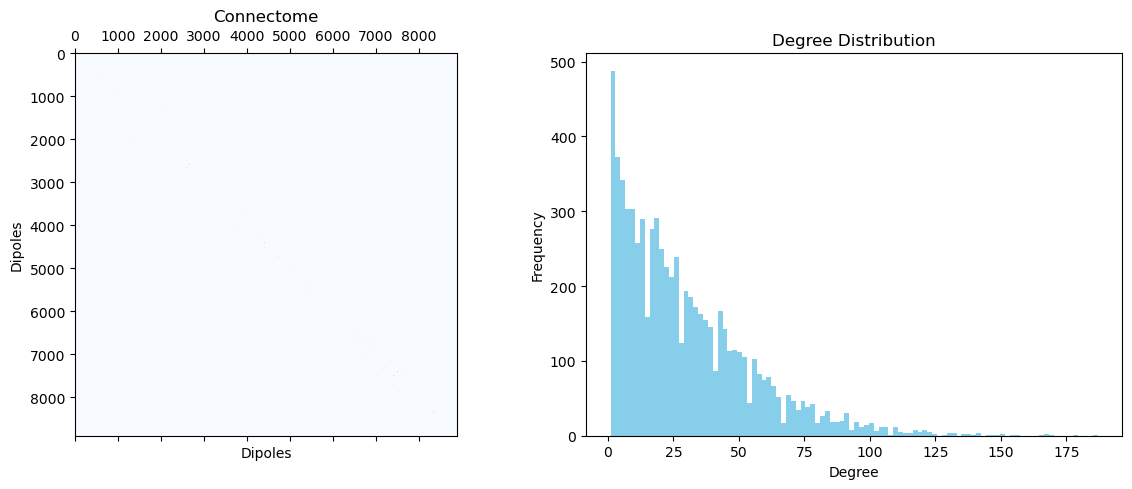

In [15]:
# sort by parcellation labels
labels = data["parc"].label_points(pos, id=True)
idx    = np.argsort(labels)
viz    = sc.todense()[idx][:,idx]

# binarize
#viz[viz>0] = 1

# compute number of isolated dipoles
stream_per_dipole = viz.sum(axis=1)
print(f"Number of isolated dipoles: {np.sum(stream_per_dipole==0)}")

# plot
mm.viz.plot_connectome(viz, name="Connectome", nonzero=True)

⚙️ **<font color=green>Smooth connectivity according to Sina Mansour et. al (2020)</font>**: The endpoints of streamlines are usually connected to multiple neurons. If the spacing between dipoles is very small, than the streamlines are most likely originating/terminating in multiple dipoles. To incorporate this in our connectomes, we can smooth the endpoints of streamlines with a gaussian kernel of approximately 2 mm. (methodology described in [Sina Mansour et. al (2020)](https://www.sciencedirect.com/science/article/pii/S1053811920311800?via%3Dihub#sec0035)) <br><br>
🚨 Only recommended if dipole spacing is smaller than 2 mm

In [9]:
# compute gaussian coefficients
sigma    = fwhm / np.sqrt(8*np.log(2))                                      # gaussian std 
max_dist = sigma * (-sp.stats.norm.ppf((1 - (1-epsilon)**(1/dim)) / 2))

geodist[geodist > max_dist] = 0
geodist.eliminate_zeros()


gaussian = -(geodist**2/(2*sigma**2))
np.exp(gaussian.data, out=gaussian.data)
gaussian += sp.sparse.eye(gaussian.shape[0], dtype=gaussian.dtype, format="csr")
gaussian /= sp.sparse.linalg.norm(gaussian, ord=1, axis=1)[:,None]

# smooth incidence (convert to numpy for faster computation)
M1s = (gaussian.T @ M1).todense()
M2s = (gaussian.T @ M2).todense()

# compute structural connectome
sc = (M1s @ M2s.T) + (M2s @ M1s.T)

#### 🌟 Visualize connectivity

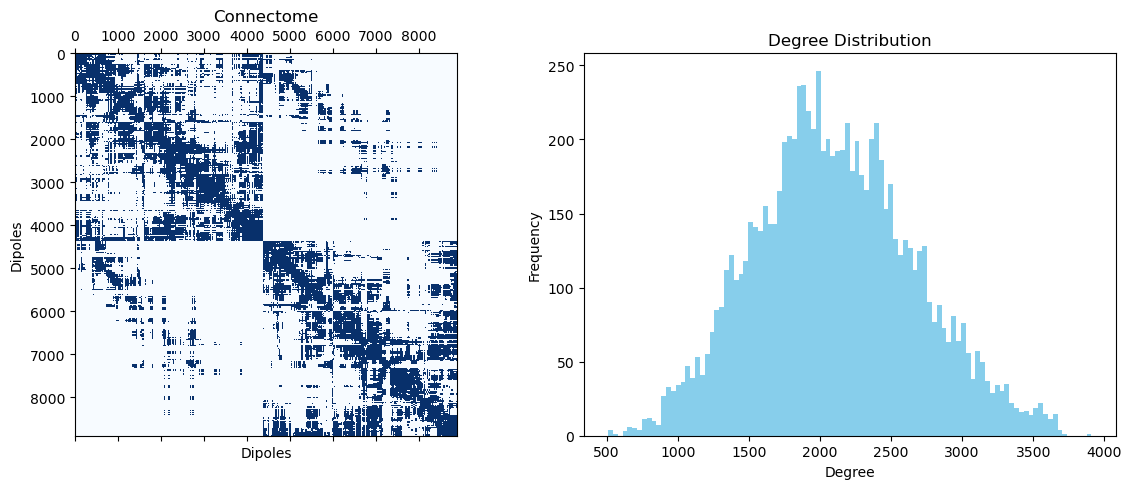

In [ ]:
# sort by parcellation labels
labels = data["parc"].label_points(pos, id=True)
idx    = np.argsort(labels)
viz    = sc[idx][:,idx]

# binarize
viz[viz>0] = 1

mm.viz.plot_connectome(viz, name="Connectome")

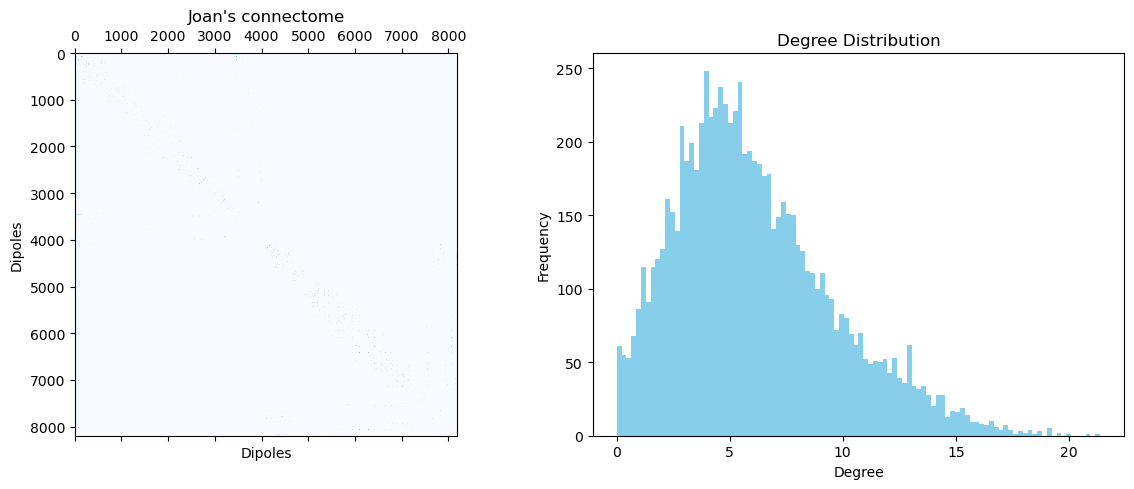

In [17]:
file = "/media/nino/DATA/VEPCON/derivatives/cscs/sub-10/sub-10-sc.npy" 
conn = np.load(file)

mm.viz.plot_connectome(conn, name="Joan's connectome")

## Connectome Spectrum Transform

⚙️ <font color=green>**Compute the Connectome Spectrum Transform (CST)**</font>: The CST is simply the Fourier Graph Transform of the connectome. The harmonics (or eigenvectors) of this transform are characteristic of the connectome. Visualize them to assess the quality of the CST.

In [ ]:
coords = [s["rr"][s["vertno"]] for s in data["src"]]
G = pygsp.graphs.Graph(sc.todense(), lap_type="normalized", coords=coords)
G.compute_fourier_basis()
cst = G.U.T

#### <font color=yellow>🌟</font> Visualize the harmonics

In [ ]:
harmonic = cst[2,:]
mm.viz.plot_brain_signal(data["src"], harmonic).show()

#### 💾 Save the SC

In [ ]:
folder = mm_dir/sub/"sc"
if folder.exists() == False:
    folder.mkdir(parents=True)

print(f"Saving SC from tractography for subject: {sub}")
np.save(folder/f"{sub}_sc-hr-tracto.npy", cst)

#### 💾 Save the CST

In [ ]:
folder = mm_dir/sub/"sc"
if folder.exists() == False:
    folder.mkdir(parents=True)

print(f"Saving CST from tractography for subject: {sub}")
np.save(folder/f"{sub}_cst-tracto.npy", cst)